# Lab 7 Presentation - Proxy Losses, Logistic Regression and ROC Curves

Josh Davis/Lucas Schwengber

Today’s goals (see the [exercise](lab7_exercise_2026.qmd) for the full
list):

1.  Classification as empirical risk minimization, and the Bayes
    classifier for a (weighted) zero-one loss.
2.  Why we do not minimize the zero-one loss directly, and use a **proxy
    loss** instead.
3.  Proxy losses such as the log loss recover
    $p(\boldsymbol{x}) = \mathbb{P}_{\,}\left(y = 1 \mid \boldsymbol{x}\right) = \mathbb{E}_{\vphantom{}}\left[y \mid \boldsymbol{x}\right]$.
    Logistic regression is ERM with the log loss.
4.  LDA: a generative route to the same kind of estimate.
5.  Turning probabilities into decisions: thresholds, false positives
    and negatives, and ROC curves.
6.  A common failure mode: with a rare class, a classifier can look
    accurate while mostly ignoring that class. ROC curves help you
    detect it.

The common thread: **every method today estimates $p(\boldsymbol{x})$,
then thresholds it.** Trees, and the $F_1$ score as one way of dealing
with rare classes, are the topics of the next lab.

LLM assistance was used during the elaboration of this presentation and
the exercise.

# Classification as empirical risk minimization

We observe features $\boldsymbol{x}\in \mathbb{R}^P$ and a label
$y \in \{0, 1\}$, and want a classifier
$\hat y(\boldsymbol{x}) \in \{0, 1\}$. The loss we usually care about
counts mistakes, possibly weighting the two kinds differently:
$$\mathscr{L}(\hat y, y) = c_{\text{FN}} \mathrm{I}\left(\hat y = 0, y = 1\right) + c_{\text{FP}} \mathrm{I}\left(\hat y = 1, y = 0\right),$$
where $c_{\text{FN}}$ is the cost of a false negative and
$c_{\text{FP}}$ the cost of a false positive. With
$c_{\text{FN}} = c_{\text{FP}} = 1$ this is the zero-one loss, the
misclassification rate.

**The Bayes classifier.** The classifier with the smallest risk
$\mathbb{E}_{\vphantom{}}\left[\mathscr{L}(\hat y(\boldsymbol{x}), y)\right]$
predicts $1$ exactly when
$$p(\boldsymbol{x}) > \frac{c_{\text{FP}}}{c_{\text{FP}} + c_{\text{FN}}}, \qquad p(\boldsymbol{x}) = \mathbb{P}_{\,}\left(y = 1 \mid \boldsymbol{x}\right).$$
You proved this in [Homework 2, Problem
1](../../assignments/hw2.qmd#risk-minimizers-for-general-zeroone-loss),
where $c_{10}$ is the cost of a false positive and $c_{01}$ the cost of
a false negative. With equal costs the threshold is $0.5$ ([Unit 2
lecture](../../lectures/unit2/unit2_classification_loss.qmd#first-version-the-ml-procedure-returns-a-category)).

So whatever the costs, the optimal decision only depends on
$p(\boldsymbol{x})$. Since $y \in \{0, 1\}$,
$$p(\boldsymbol{x}) = \mathbb{P}_{\,}\left(y = 1 \mid \boldsymbol{x}\right) = \mathbb{E}_{\vphantom{}}\left[y \mid \boldsymbol{x}\right],$$
the regression function of $y$ on $\boldsymbol{x}$. **Estimating
$p(\boldsymbol{x})$ is a regression problem**, and once we have an
estimate $q(\boldsymbol{x})$, we can plug it into the Bayes rule for
whatever costs we face.

## A practice world

As in Lab 4, we use simulated data in which we know $p(\boldsymbol{x})$,
so that we can draw the true decision boundary
$\{\boldsymbol{x}: p(\boldsymbol{x}) = 0.5\}$ and compare any method
with the best possible one. Here each class is a Gaussian with the same
covariance, and both classes are equally likely. **How do we know the
true boundary?** We chose how the data are generated: class 0 is
$N(\boldsymbol{\mu}_0, \boldsymbol{\Sigma})$ and class 1 is
$N(\boldsymbol{\mu}_1, \boldsymbol{\Sigma})$, each with probability
$1/2$, with $\boldsymbol{\mu}_0$, $\boldsymbol{\mu}_1$ and
$\boldsymbol{\Sigma}$ written in `simulator.py`. Knowing these
distributions, Bayes’ rule gives $p(\boldsymbol{x})$ exactly at every
$\boldsymbol{x}$ (we will see how in the LDA section below), and the
true boundary is the curve where it equals $0.5$, which here is a
straight line. With real data we never know these distributions, so we
can only estimate $p(\boldsymbol{x})$. The line
`world = PracticeWorld("shared")` below creates this world as a Python
object, which can draw training data from it (`world.simulate`), tell us
the true $p(\boldsymbol{x})$ (`world.true_prob`), and draw the true
decision boundary (`world.plot_true_boundary`).

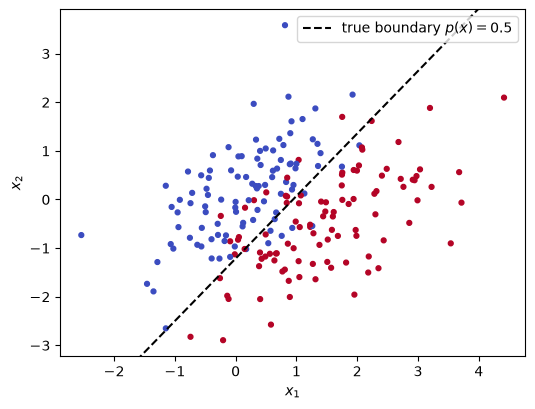

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score

sys.path.insert(0, "../../datasets/classification_lab")    # in your notebook: download simulator.py as in the exercise
from simulator import PracticeWorld


def add_boundary(model, X, ax, color, label, level=0.5):
    """Draw the curve where the model's predicted probability equals `level`."""
    DecisionBoundaryDisplay.from_estimator(model, X, response_method="predict_proba",
                                           plot_method="contour", levels=[level], ax=ax, colors=color)
    ax.plot([], [], color=color, label=label)    # empty line, so the boundary shows up in the legend


world = PracticeWorld("shared")
X, y = world.simulate(200, seed=1)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=12)
world.plot_true_boundary(ax)
ax.plot([], [], "k--", label="true boundary $p(x) = 0.5$")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.legend()
plt.show()

# Why not minimize the zero-one loss directly?

ERM with the zero-one loss would choose, among linear classifiers
$\hat y(\boldsymbol{x}) = \mathrm{I}\left(\beta_0 + \boldsymbol{x}^\intercal\boldsymbol{\beta}> 0\right)$,
the one with the fewest training mistakes. Two problems:

1.  **It cannot be optimized with gradients.** The training error only
    changes when the boundary crosses a training point, so as a function
    of $(\beta_0, \boldsymbol{\beta})$ it is a step function: flat
    almost everywhere, with jumps in between. Its gradient is zero
    wherever it exists, and finding the minimum is a combinatorial
    search.
2.  **It only sees the predicted label, not the probability.** Two
    models with the same boundary but very different confidence have
    exactly the same zero-one loss. So the zero-one loss cannot tell us
    $p(\boldsymbol{x})$, and a classifier fit to minimize it cannot be
    re-thresholded when the costs change.

Below we start from the logistic regression fit
$q(\boldsymbol{x}) = \mathrm{Expit}\left(\hat\beta_0 + \boldsymbol{x}^\intercal\hat{\boldsymbol{\beta}}\right)$
and perturb it in two ways, recording the training zero-one loss and the
training log loss:

- **Left:** shift the intercept, $\hat\beta_0 + \delta$, which slides
  the boundary.
- **Right:** scale all coefficients,
  $s \cdot (\hat\beta_0, \hat{\boldsymbol{\beta}})$, which keeps the
  boundary fixed but makes the probabilities more ($s > 1$) or less
  ($s < 1$) confident.

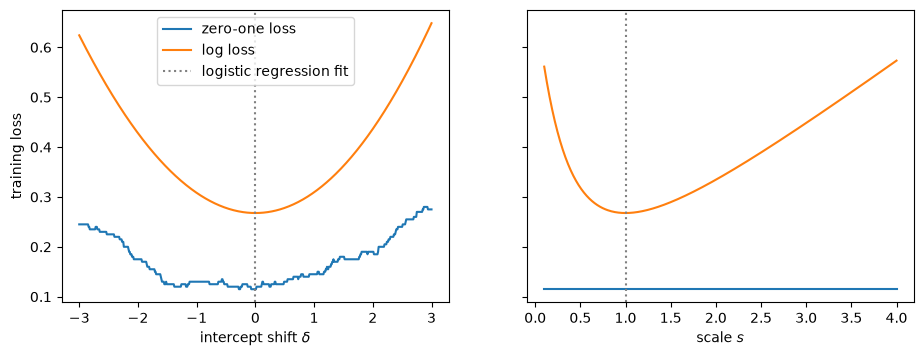

In [2]:
logistic = LogisticRegression(C=np.inf).fit(X, y)    # C=np.inf: no regularization
b0, b = logistic.intercept_[0], logistic.coef_[0]


def train_losses(q):
    """Training zero-one loss (predicting q > 0.5) and log loss of probabilities q."""
    q = np.clip(q, 1e-12, 1 - 1e-12)
    return np.mean((q > 0.5) != y), -np.mean(y * np.log(q) + (1 - y) * np.log(1 - q))


shifts = np.linspace(-3, 3, 601)
scales = np.linspace(0.1, 4, 400)
by_shift = np.array([train_losses(expit(b0 + d + X @ b)) for d in shifts])
by_scale = np.array([train_losses(expit(s * (b0 + X @ b))) for s in scales])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, grid, res, xlabel, fitted in [(axes[0], shifts, by_shift, r"intercept shift $\delta$", 0),
                                      (axes[1], scales, by_scale, r"scale $s$", 1)]:
    ax.plot(grid, res[:, 0], label="zero-one loss")
    ax.plot(grid, res[:, 1], label="log loss")
    ax.axvline(fitted, color="gray", ls=":", label="logistic regression fit")
    ax.set_xlabel(xlabel)
axes[0].set_ylabel("training loss"); axes[0].legend()
plt.show()

On the left, the zero-one loss is a jagged step function, while the log
loss is smooth with a single minimum. On the right, the zero-one loss
does not change at all, because the boundary never moves, while the log
loss clearly prefers one level of confidence.

# Proxy losses

Instead, we fit a probability $q(\boldsymbol{x})$ with a smooth **proxy
loss**, then threshold it. The two standard choices are
$$\mathscr{L}_{\text{log}}(q, y) = -y \log q- (1 - y) \log(1 - q), \qquad \mathscr{L}_{\text{sq}}(q, y) = (q- y)^2.$$
What makes them good proxies is what they are minize. Fix
$\boldsymbol{x}$, write $p = p(\boldsymbol{x})$, and average over the
random label $y \sim \text{Bernoulli}(p)$:
$$\mathbb{E}_{\vphantom{}}\left[\mathscr{L}_{\text{log}}(q, y) \mid \boldsymbol{x}\right] = -p \log q- (1 - p) \log(1 - q), \qquad \mathbb{E}_{\vphantom{}}\left[\mathscr{L}_{\text{sq}}(q, y) \mid \boldsymbol{x}\right] = (q- p)^2 + p(1 - p).$$
Both are minimized at $q= p$: **the risk minimizer of either proxy loss
is the true probability
$p(\boldsymbol{x}) = \mathbb{E}_{\vphantom{}}\left[y \mid \boldsymbol{x}\right]$.**
For the squared loss this is exactly the regression result from Unit 1.
Losses with this property are called *proper scoring rules* ([Unit 2
lecture](../../lectures/unit2/unit2_classification_loss.qmd#second-version-the-ml-procedure-returns-a-probability),
and the “Proper scoring rules” problem in [Homework
2](../../assignments/hw2.qmd)).

**Compare this with the zero-one loss.** If we predict
$\hat y = \mathrm{I}\left(q> 0.5\right)$, the expected zero-one loss at
$\boldsymbol{x}$ is $1 - p$ when $q> 0.5$ and $p$ when $q\le 0.5$: it
only depends on which side of $0.5$ the prediction $q$ falls, not on $q$
itself. With $p = 0.3$, the predictions $q= 0.01$, $q= 0.3$ and
$q= 0.49$ all have the same expected zero-one loss, so minimizing the
zero-one loss gives us no reason to prefer the correct value $q= 0.3$.
That is a problem as soon as the costs change: with
$c_{\text{FN}} = 9 \, c_{\text{FP}}$, the Bayes rule needs to know
whether $p(\boldsymbol{x}) > 0.1$, and a model trained on the zero-one
loss cannot tell us that, while one trained on a proxy loss can. The
plot below shows the three expected losses for $p = 0.3$.

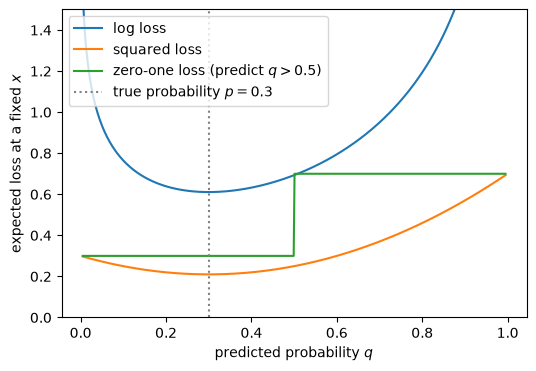

In [3]:
p = 0.3
q = np.linspace(0.005, 0.995, 500)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(q, -p * np.log(q) - (1 - p) * np.log(1 - q), label="log loss")
ax.plot(q, (q - p) ** 2 + p * (1 - p), label="squared loss")
ax.plot(q, np.where(q > 0.5, 1 - p, p), label="zero-one loss (predict $q > 0.5$)")
ax.axvline(p, color="gray", ls=":", label=f"true probability $p = {p}$")
ax.set_ylim(0, 1.5); ax.set_xlabel("predicted probability $q$"); ax.set_ylabel("expected loss at a fixed $x$")
ax.legend(); plt.show()

## Logistic regression is ERM with the log loss

Logistic regression models
$q(\boldsymbol{x}) = \mathrm{Expit}\left(\beta_0 + \boldsymbol{x}^\intercal\boldsymbol{\beta}\right)$
and chooses $\beta_0, \boldsymbol{\beta}$ to minimize the average
training log loss. Writing
$f = \beta_0 + \boldsymbol{x}^\intercal\boldsymbol{\beta}$, the loss
becomes $-y f + \log(1 + e^{f})$, which is smooth and convex in
$(\beta_0, \boldsymbol{\beta})$, so it can be minimized reliably. This
gives the **plug-in recipe** we use for the rest of the lab:

1.  estimate $p(\boldsymbol{x})$ by minimizing a proxy loss,
2.  predict $\hat y = 1$ when $q(\boldsymbol{x})$ exceeds the threshold
    that the costs call for.

In scikit-learn, `LogisticRegression` adds a ridge penalty by default,
with strength $1/C$. We use `C=np.inf` to turn it off.

# LDA: a generative route to $p(\boldsymbol{x})$

Logistic regression models
$\mathbb{P}_{\,}\left(y \mid \boldsymbol{x}\right)$ directly
(*discriminative*). Linear discriminant analysis (LDA) is *generative*:
it models how $\boldsymbol{x}$ is distributed within each class,
$f_k(\boldsymbol{x})$ (the density of $\boldsymbol{x}$ given $y = k$),
and how common each class is,
$\pi_k = \mathbb{P}_{\,}\left(y = k\right)$, then flips the conditioning
with Bayes’ rule.

**The trick: flipping the conditioning.** The joint density of
$\boldsymbol{x}$ and $y = k$ can be factored in two ways, conditioning
on either variable:
$$\mathbb{P}_{\,}\left(y = k \mid \boldsymbol{x}\right) \, f(\boldsymbol{x}) = f_k(\boldsymbol{x}) \, \pi_k,$$
where $f(\boldsymbol{x})$ is the marginal density of $\boldsymbol{x}$,
ignoring the label. By the law of total probability, the marginal is a
mixture of the two class densities, weighted by how common each class
is:
$f(\boldsymbol{x}) = \pi_0 f_0(\boldsymbol{x}) + \pi_1 f_1(\boldsymbol{x})$.
Dividing by $f(\boldsymbol{x})$ and taking $k = 1$,
$$p(\boldsymbol{x}) = \mathbb{P}_{\,}\left(y = 1 \mid \boldsymbol{x}\right) = \frac{\pi_1 f_1(\boldsymbol{x})}{f(\boldsymbol{x})} = \frac{\pi_1 f_1(\boldsymbol{x})}{\pi_0 f_0(\boldsymbol{x}) + \pi_1 f_1(\boldsymbol{x})}.$$

LDA assumes that each class is Gaussian with a **common** covariance,
$\boldsymbol{x}\mid y = k \sim N(\boldsymbol{\mu}_k, \boldsymbol{\Sigma})$,
and estimates $\pi_k$, $\boldsymbol{\mu}_k$ and $\boldsymbol{\Sigma}$ by
the class proportions, the class means and the pooled within-class
covariance (ESL Section 4.3). Plugging Gaussians into Bayes’ rule, the
quadratic terms
$-\frac12 \boldsymbol{x}^\intercal\boldsymbol{\Sigma}^{-1}\boldsymbol{x}$
cancel because both classes share $\boldsymbol{\Sigma}$, and the log
odds are linear in $\boldsymbol{x}$ (ESL eq. 4.9):
$$\log \frac{p(\boldsymbol{x})}{1 - p(\boldsymbol{x})} = \underbrace{\log\frac{\pi_1}{\pi_0} - \frac{1}{2}(\boldsymbol{\mu}_1 + \boldsymbol{\mu}_0)^\intercal\boldsymbol{\Sigma}^{-1} (\boldsymbol{\mu}_1 - \boldsymbol{\mu}_0)}_{\beta_0} + \boldsymbol{x}^\intercal\underbrace{\boldsymbol{\Sigma}^{-1}(\boldsymbol{\mu}_1 - \boldsymbol{\mu}_0)}_{\boldsymbol{\beta}}.$$
So LDA ends up with exactly the logistic regression form,
$p(\boldsymbol{x}) = \mathrm{Expit}\left(\beta_0 + \boldsymbol{x}^\intercal\boldsymbol{\beta}\right)$;
you worked through this connection in the “Logistic regression as
Gaussian generative modeling” problem of [Homework
2](../../assignments/hw2.qmd#logistic-regression-as-gaussian-generative-modeling).

**Same form, different estimates** (ESL Section 4.4.5). Logistic
regression maximizes the likelihood of the labels given the features,
and makes no assumption about how $\boldsymbol{x}$ is distributed. LDA
fits the full joint distribution of $(\boldsymbol{x}, y)$, so every
observation, including ones far from the boundary, affects its estimate.
When the Gaussian assumption holds, this makes LDA more efficient; when
it fails, it can pull the LDA boundary away. ESL: “It is generally felt
that logistic regression is a safer, more robust bet than the LDA model,
relying on fewer assumptions.”

Here LDA’s assumptions hold exactly, and the two fits nearly coincide:

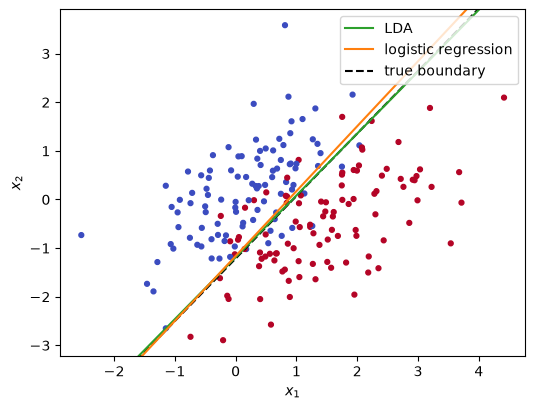

LDA       intercept  -2.80   coefficients [ 2.99 -2.35]   true risk (log loss) 0.293
logistic  intercept  -2.97   coefficients [ 3.41 -2.55]   true risk (log loss) 0.299
Bayes risk: 0.292

In [4]:
lda = LinearDiscriminantAnalysis().fit(X, y)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=12)
world.plot_true_boundary(ax)
add_boundary(lda, X, ax, "C2", "LDA")
add_boundary(logistic, X, ax, "C1", "logistic regression")
ax.plot([], [], "k--", label="true boundary")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.legend()
plt.show()

for name, model in [("LDA", lda), ("logistic", logistic)]:
    print(f"{name:8s}  intercept {model.intercept_[0]:6.2f}   coefficients {np.round(model.coef_[0], 2)}   "
          f"true risk (log loss) {world.true_risk(model):.3f}")
print(f"Bayes risk: {world.bayes_risk():.3f}")

In the exercise you will find a world where the difference matters.

# From probabilities to decisions: thresholds and ROC curves

For any threshold $t$, the classifier
$\hat y = \mathrm{I}\left(q(\boldsymbol{x}) > t\right)$ makes two kinds
of mistakes. Counting on some set of observations (usually a test set)
with $P$ positives ($y = 1$) and $N$ negatives ($y = 0$):

|              | $y = 1$             | $y = 0$             |
|--------------|---------------------|---------------------|
| $\hat y = 1$ | true positive (TP)  | false positive (FP) |
| $\hat y = 0$ | false negative (FN) | true negative (TN)  |

This matrix is also known as a [confusion
matrix](https://en.wikipedia.org/wiki/Confusion_matrix).

The two rates we track ([Unit 2 lecture on false positives and
negatives](../../lectures/unit2/unit2_false_positives_negatives.qmd#some-key-terminology))
are each computed **within one class**:
$$\text{TPR} = \frac{\text{TP}}{P} \;\;(\text{fraction of positives we catch}), \qquad \text{FPR} = \frac{\text{FP}}{N} \;\;(\text{fraction of negatives we wrongly flag}).$$
In the medical language that ESL uses (Section 9.2.5), the TPR is the
*sensitivity* and $1 - \text{FPR}$ is the *specificity*. Note that,
since the columns add up to fixed counts, these two numbers suffice to
describe the full performance of the model. This contains strictly more
information than the accuracy which is a sum of the diagonal and in
being a single number misses some information from the matrix.

**Rejection regions.** The set where we predict 1,
$R_t = \{\boldsymbol{x}: q(\boldsymbol{x}) > t\}$, plays the role of a
rejection region in a hypothesis test of “$y = 0$” against “$y = 1$”:
the FPR is the probability of rejecting when $y = 0$ (the size, or type
I error rate), and the TPR is the probability of rejecting when $y = 1$
(the power). For logistic regression, $R_t$ has a simple shape. Since
$q(\boldsymbol{x}) = \mathrm{Expit}\left(\beta_0 + \boldsymbol{x}^\intercal\boldsymbol{\beta}\right)$
and the expit function is increasing, we can apply its inverse,
$\mathrm{Logit}\left(t\right) = \log\frac{t}{1 - t}$, to both sides of
$q(\boldsymbol{x}) > t$:
$$q(\boldsymbol{x}) > t \iff \beta_0 + \boldsymbol{x}^\intercal\boldsymbol{\beta}> \mathrm{Logit}\left(t\right) \iff \boldsymbol{x}^\intercal\boldsymbol{\beta}> \mathrm{Logit}\left(t\right) - \beta_0.$$
So $R_t$ is a half-plane, and its boundary is the line
$\{\boldsymbol{x}: \boldsymbol{x}^\intercal\boldsymbol{\beta}= \mathrm{Logit}\left(t\right) - \beta_0\}$.
Changing $t$ only changes the constant
$\mathrm{Logit}\left(t\right) - \beta_0$ on the right-hand side, not
$\boldsymbol{\beta}$, and $\boldsymbol{\beta}$ is what sets the
direction of the line (it is perpendicular to it). So all these
boundaries are parallel lines, just like $\{x_2 = c\}$ for different
values of $c$: lowering $t$ slides the line towards class 0 and makes
$R_t$ bigger, and $t = 0.5$ gives $\mathrm{Logit}\left(0.5\right) = 0$,
the usual decision boundary.

**The ROC curve** plots $(\text{FPR}(t), \text{TPR}(t))$ for every
threshold $t$ at once. Lowering $t$ moves up and to the right: we catch
more positives, but incorrectly flag as positive more negatives. By the
Bayes rule, each threshold corresponds to a choice of costs,
$t = c_{\text{FP}} / (c_{\text{FP}} + c_{\text{FN}})$, so the ROC curve
is the menu of classifiers we would pick for every possible ratio of
costs. This is exactly how ESL draws the ROC curve of its spam
classifier (Section 9.2.5, Figure 9.6): it varies the relative loss of
the two kinds of errors, applies the Bayes rule, and records the
sensitivity and specificity. The [Unit 2
lecture](../../lectures/unit2/unit2_false_positives_negatives.qmd#the-roc-curve-and-trading-off-errors)
makes the link precise: the point that minimizes the expected cost
$c_{\text{FP}} \cdot \text{FP} + c_{\text{FN}} \cdot \text{FN}$ is where
the slope of the ROC curve equals
$\frac{N}{P} \cdot \frac{c_{\text{FP}}}{c_{\text{FN}}}$.

A useless classifier, whose prediction ignores $\boldsymbol{x}$, lies on
the diagonal, and a curve below the diagonal can be flipped into one
above it ([Homework 2, “ROC curves of bad
classifiers”](../../assignments/hw2.qmd#roc-curves-of-bad-classifiers)).
A perfect classifier goes through the top-left corner. The area under
the curve (AUC) summarizes how well $q$ *ranks* the two classes,
regardless of the threshold: it equals the probability that a randomly
chosen positive gets a higher $q$ than a randomly chosen negative (the
Mann-Whitney statistic, ESL Section 9.2.5).

**Choosing the threshold in practice.** The threshold is a
hyperparameter of the classifier. When the costs are known and $q$ is a
good estimate of $p$, the Bayes rule tells us which threshold to use;
otherwise, we choose it like any other hyperparameter, with cross
validation on the training data (Labs 4 and 5), and use the test set
only to evaluate the final choice. You will do this in the exercise.

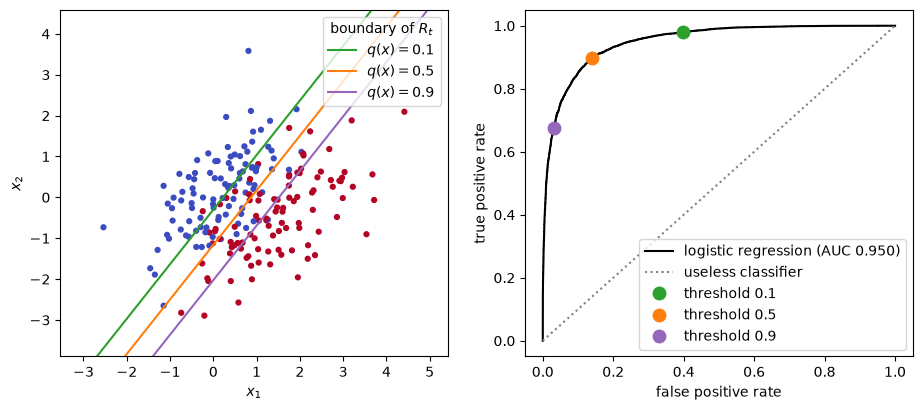

In [5]:
X_test, y_test = world.simulate(20_000, seed=2)
q_test = logistic.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, q_test)
thresholds = [0.1, 0.5, 0.9]
colors = ["C2", "C1", "C4"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=12)
for t, color in zip(thresholds, colors):
    add_boundary(logistic, X, axes[0], color, f"$q(x) = {t}$", level=t)
axes[0].set_xlabel("$x_1$"); axes[0].set_ylabel("$x_2$"); axes[0].legend(title="boundary of $R_t$")

axes[1].plot(fpr, tpr, color="k", label=f"logistic regression (AUC {roc_auc_score(y_test, q_test):.3f})")
axes[1].plot([0, 1], [0, 1], color="gray", ls=":", label="useless classifier")
for t, color in zip(thresholds, colors):
    pred = q_test > t
    axes[1].plot(pred[y_test == 0].mean(), pred[y_test == 1].mean(), "o", color=color, ms=9, label=f"threshold {t}")
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].legend()
plt.show()

# When one class is rare

Now keep the two class distributions exactly as before, but make class 1
rare: $\mathbb{P}_{\,}\left(y = 1\right) = 0.05$. We fit logistic
regression on 2,000 observations and look at a large test set.

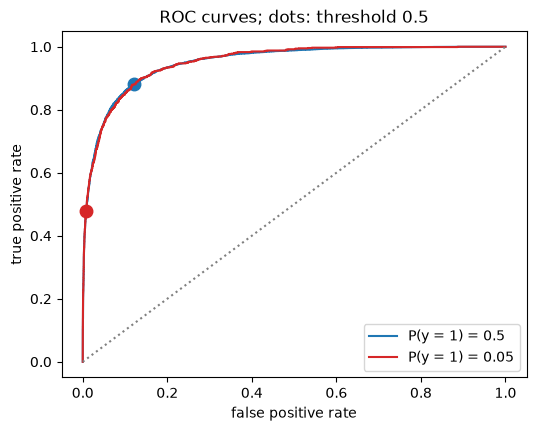

P(y=1)   accuracy at 0.5   accuracy of 'always 0'   TPR at 0.5   AUC
   0.5             0.880                    0.502         0.88   0.951
  0.05             0.966                    0.950         0.48   0.951

In [6]:
rows = {}
fig, ax = plt.subplots(figsize=(6, 4.5))
for prior, color in [(0.5, "C0"), (0.05, "C3")]:
    w = PracticeWorld("shared", prior=prior)
    X_tr, y_tr = w.simulate(2000, seed=0)
    X_te, y_te = w.simulate(20_000, seed=1)
    q_te = LogisticRegression(C=np.inf).fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
    pred = q_te > 0.5
    rows[prior] = (np.mean(pred == y_te), np.mean(y_te == 0), pred[y_te == 1].mean(), roc_auc_score(y_te, q_te))
    fpr, tpr, _ = roc_curve(y_te, q_te)
    ax.plot(fpr, tpr, color=color, label=f"P(y = 1) = {prior}")
    ax.plot(pred[y_te == 0].mean(), pred[y_te == 1].mean(), "o", color=color, ms=9)
ax.plot([0, 1], [0, 1], color="gray", ls=":")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("ROC curves; dots: threshold 0.5"); ax.legend()
plt.show()

print("P(y=1)   accuracy at 0.5   accuracy of 'always 0'   TPR at 0.5   AUC")
for prior, (acc, acc0, tpr05, auc) in rows.items():
    print(f"{prior:6}   {acc:15.3f}   {acc0:22.3f}   {tpr05:10.2f}   {auc:.3f}")

Three things to notice:

- **Accuracy hides the problem.** With a rare class, accuracy is
  dominated by the majority class: “always predict 0” is already 95%
  accurate, and our model barely beats it.
- **The ROC curve does not change.** TPR and FPR are each computed
  within one class, so they do not depend on how common the classes are.
  In the LDA formula (ESL eq. 4.9), making class 1 rarer only lowers
  $\log(\pi_1 / \pi_0)$ in the intercept $\beta_0$: as in the previous
  section, the boundary slides without rotating, so the model ranks
  observations exactly as before.
- **The operating point does.** At threshold 0.5 the model now flags
  very few observations, and the dot slides towards the bottom-left
  corner: it misses about half of the rare class. In the extreme, a
  classifier that predicts 0 for everyone sits at $(0, 0)$, with
  excellent accuracy and no use at all.

**Why does the 0.5 threshold land there? It is doing what the zero-one
loss asks.** With equal costs, the slope result from the lecture says
that the point on the ROC curve with the fewest mistakes is where the
slope equals $N / P$, the ratio of negatives to positives. With
$\mathbb{P}_{\,}\left(y = 1\right) = 0.05$ that slope is 19, which the
curve only reaches on its steep part, near the bottom-left. So flagging
very little of the rare class is the *right* answer for accuracy, and
the model is not broken. The problem is that accuracy is rarely what we
care about when one class is rare: missing a rare disease case or a
fraudulent transaction usually costs much more than a false alarm.

**Test-set estimates are noisy for the rare class.** As in Lab 4, TPR
and FPR are estimates from a finite test set. The TPR is estimated from
the $P$ positives only, with binomial standard error
$\sqrt{\text{TPR}(1 - \text{TPR}) / P}$ (ESL Section 9.2.5 does a
similar calculation for its spam ROC curve). With
$\mathbb{P}_{\,}\left(y = 1\right) = 0.05$, our 20,000 test observations
contain only about 1,000 positives, and with
$\mathbb{P}_{\,}\left(y = 1\right) = 0.02$ only about 400.

So: when one class is rare, do not judge a classifier by its accuracy.
Look at where it sits on the ROC curve (equivalently, its TPR and FPR)
and ask whether that matches what you need. If you know the costs, the
Bayes rule above tells you which threshold to use. If you do not, you
need a metric that cares about the rare class, such as the $F_1$ score,
which is the topic of the next lab.

# Summary

- The optimal decision only depends on
  $p(\boldsymbol{x}) = \mathbb{E}_{\vphantom{}}\left[y \mid \boldsymbol{x}\right]$,
  thresholded at $c_{\text{FP}} / (c_{\text{FP}} + c_{\text{FN}})$.
- We cannot minimize the zero-one loss directly: it is a step function
  of the parameters and ignores probabilities. Proper proxy losses (log
  loss, squared loss) are smooth and are minimized by
  $p(\boldsymbol{x})$.
- Logistic regression is ERM with the log loss over
  $\mathrm{Expit}\left(\beta_0 + \boldsymbol{x}^\intercal\boldsymbol{\beta}\right)$.
  LDA reaches the same linear form generatively, by modeling each class
  as a Gaussian and applying Bayes’ rule.
- A threshold turns $q(\boldsymbol{x})$ into a classifier; the ROC curve
  shows the TPR/FPR tradeoff over all thresholds.
- With a rare class, accuracy can look great while the classifier
  ignores that class. Check the operating point on the ROC curve.